In [7]:
%pip install pandas numpy matplotlib seaborn nltk scikit-learn spacy

Note: you may need to restart the kernel to use updated packages.


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import spacy

from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [9]:
# GitHub raw dataset URL
url = "https://raw.githubusercontent.com/aniketnandi/automated-resume-screening/main/data/UpdatedResumeDataSet.csv"

# Load dataset
df = pd.read_csv(url)

print("Dataset successfully loaded!")
print("Dataset shape:", df.shape)

df.head()

Dataset successfully loaded!
Dataset shape: (962, 2)


,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \nMay 2013 to May 2017 B.E ...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \n MCA YMCAUST, Faridabad..."


In [10]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 962 entries, 0 to 961
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Category  962 non-null    str  
 1   Resume    962 non-null    str  
dtypes: str(2)
memory usage: 2.9 MB


In [11]:
# Check column names
print(df.columns.tolist())

['Category', 'Resume']


In [12]:
# Missing values
print(df.isnull().sum())

Category    0
Resume      0
dtype: int64


In [13]:
# Duplicate records
print("Duplicate records:", df.duplicated().sum())

# Unique resumes
print("Unique resumes:", df['Resume'].nunique())

Duplicate records: 796
Unique resumes: 166


In [16]:
# Number of resumes per category
category_counts = df['Category'].value_counts()

print(category_counts)

Category
Java Developer               84
Testing                      70
DevOps Engineer              55
Python Developer             48
Web Designing                45
HR                           44
Hadoop                       42
Data Science                 40
Mechanical Engineer          40
Sales                        40
Operations Manager           40
ETL Developer                40
Blockchain                   40
Arts                         36
Database                     33
Health and fitness           30
Electrical Engineering       30
PMO                          30
Business Analyst             28
DotNet Developer             28
Automation Testing           26
Network Security Engineer    25
Civil Engineer               24
SAP Developer                24
Advocate                     20
Name: count, dtype: int64


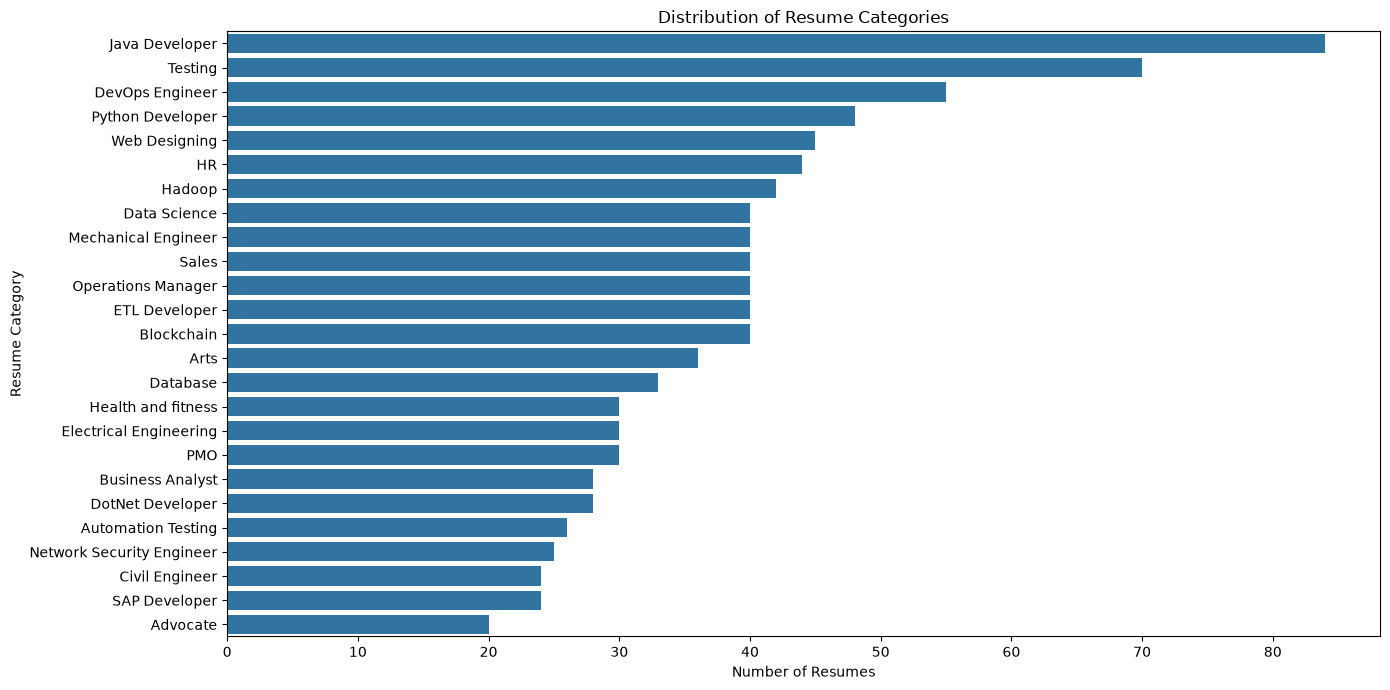

In [17]:
plt.figure(figsize=(14, 7))

sns.countplot(
    data=df,
    y='Category',
    order=df['Category'].value_counts().index
)

plt.title("Distribution of Resume Categories")
plt.xlabel("Number of Resumes")
plt.ylabel("Resume Category")

plt.tight_layout()
plt.show()

In [18]:
def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Keep technical symbols such as +, # and .
    text = re.sub(r'[^a-z0-9+#.\s]', ' ', text)

    # Remove excessive whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [19]:
df = df.dropna(subset=['Resume']).copy()

df['Cleaned_Resume'] = df['Resume'].apply(clean_text)

df[['Category', 'Cleaned_Resume']].head()

,Category,Cleaned_Resume
0,Data Science,skills programming languages python pandas num...
1,Data Science,education details may 2013 to may 2017 b.e uit...
2,Data Science,areas of interest deep learning control system...
3,Data Science,skills r python sap hana tableau sap hana sql ...
4,Data Science,education details mca ymcaust faridabad haryan...


In [20]:
df = df.drop_duplicates(
    subset=['Cleaned_Resume']
).reset_index(drop=True)

print("Dataset after removing duplicates:", df.shape)

Dataset after removing duplicates: (166, 3)


In [21]:
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     -- ------------------------------------- 0.8/12.8 MB 2.0 MB/s eta 0:00:07
     ---- ----------------------------------- 1.3/12.8 MB 2.3 MB/s eta 0:00:06
     ---- ----------------------------------- 1.6/12.8 MB 2.2 MB/s eta 0:00:06
     ----- ---------------------------------- 1.8/12.8 MB 2.0 MB/s eta 0:00:06
     ------ --------------------------------- 2.1/12.8 MB 1.8 MB/s eta 0:00:07
     ------- -------------------------------- 2.4/12.8 MB 1.6 MB/s eta 0:00:07
     -------- ------------------------------- 2.6/12.8 MB 1.6 MB/s eta 0:00:07
     --------- ------------------------------ 2.9/12.8 MB 1.5 MB/s eta 0:00:07
     --------- ------------------------------ 3.1/12.8 MB 1.5 MB/s eta 0:00:07
     ---------- ----------------------------- 3.4/12.8 MB 1.5 MB/s eta 0:00:07
     ----------- ---------------------------- 3.7/12.8 MB 1.5 MB/s

In [22]:
nlp = spacy.load("en_core_web_sm")

In [23]:
def preprocess_text(text):

    doc = nlp(text)

    tokens = []

    for token in doc:

        if (
            not token.is_stop
            and not token.is_punct
            and not token.is_space
            and len(token.text) > 1
        ):

            tokens.append(token.lemma_)

    return " ".join(tokens)

In [24]:
df['Processed_Resume'] = df['Cleaned_Resume'].apply(
    preprocess_text
)

df[['Cleaned_Resume', 'Processed_Resume']].head()

,Cleaned_Resume,Processed_Resume
0,skills programming languages python pandas num...,skills program language python panda numpy sci...
1,education details may 2013 to may 2017 b.e uit...,education detail 2013 2017 b.e uit rgpv data s...
2,areas of interest deep learning control system...,area interest deep learn control system design...
3,skills r python sap hana tableau sap hana sql ...,skill python sap hana tableau sap hana sql sap...
4,education details mca ymcaust faridabad haryan...,education detail mca ymcaust faridabad haryana...


In [25]:
skills = [
    'python',
    'java',
    'javascript',
    'c++',
    'c#',
    'sql',
    'mysql',
    'postgresql',
    'mongodb',

    'machine learning',
    'deep learning',
    'artificial intelligence',
    'natural language processing',
    'computer vision',

    'pandas',
    'numpy',
    'scikit-learn',
    'tensorflow',
    'pytorch',

    'django',
    'flask',
    'fastapi',
    'asp.net',
    'spring boot',

    'docker',
    'kubernetes',
    'aws',
    'azure',
    'git',
    'github',

    'rest api',
    'api development',
    'data analysis',
    'data visualization',
    'data science',

    'html',
    'css',
    'react',
    'angular',

    'power bi',
    'tableau',
    'excel',

    'linux',
    'machine learning algorithms',
    'neural networks',
    'statistical analysis'
]

In [26]:
def extract_skills(text):

    extracted_skills = []

    for skill in skills:

        pattern = (
            r'(?<![a-z0-9])'
            + re.escape(skill)
            + r'(?![a-z0-9])'
        )

        if re.search(pattern, text, re.IGNORECASE):

            extracted_skills.append(skill)

    return extracted_skills

In [27]:
df['Extracted_Skills'] = df['Cleaned_Resume'].apply(
    extract_skills
)

df[['Category', 'Extracted_Skills']].head(10)

,Category,Extracted_Skills
0,Data Science,"[python, java, javascript, sql, mysql, machine..."
1,Data Science,"[python, machine learning, aws, github]"
2,Data Science,"[python, java, sql, mysql, machine learning, d..."
3,Data Science,"[python, c#, sql, machine learning, deep learn..."
4,Data Science,"[python, java, data analysis, data science]"
5,Data Science,"[python, machine learning, data science, html,..."
6,Data Science,"[python, machine learning, data visualization,..."
7,Data Science,"[python, java, c++, sql, mysql, machine learni..."
8,Data Science,"[python, sql, mysql, machine learning, deep le..."
9,Data Science,"[python, machine learning, aws, data analysis,..."


In [28]:
all_skills = [
    skill
    for resume_skills in df['Extracted_Skills']
    for skill in resume_skills
]

skill_counts = Counter(all_skills)

skill_frequency = pd.DataFrame(
    skill_counts.items(),
    columns=['Skill', 'Frequency']
).sort_values(
    by='Frequency',
    ascending=False
)

skill_frequency.head(15)

,Skill,Frequency
3,sql,55
1,java,43
4,mysql,30
0,python,29
15,html,29
2,javascript,23
24,linux,23
23,excel,21
27,c++,19
16,css,18


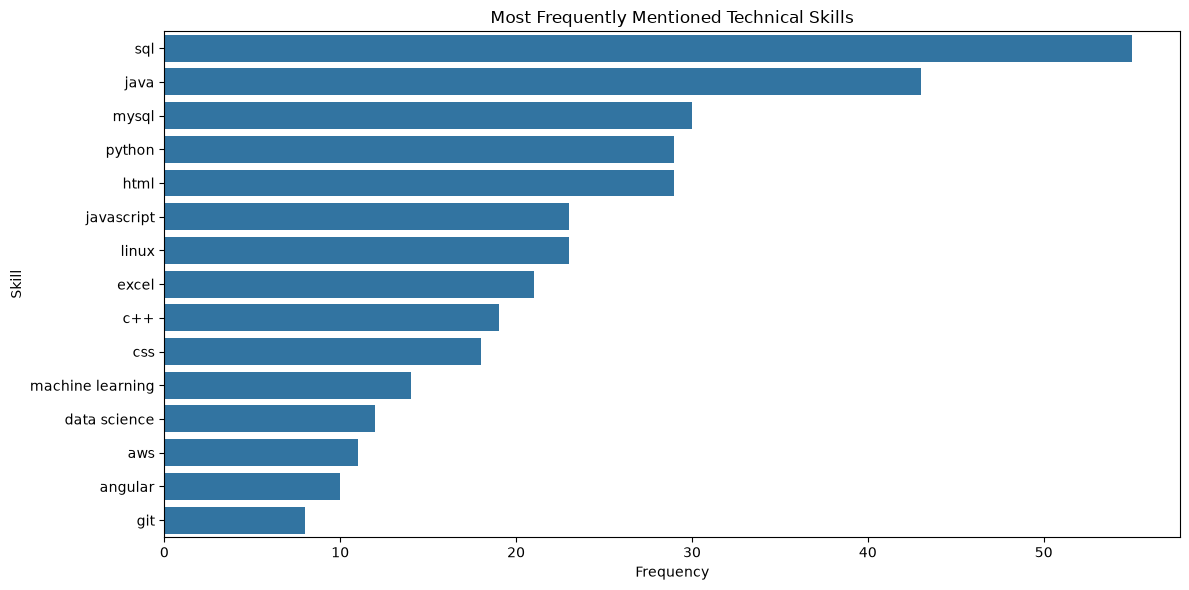

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=skill_frequency.head(15),
    x='Frequency',
    y='Skill'
)

plt.title("Most Frequently Mentioned Technical Skills")
plt.tight_layout()
plt.show()

In [30]:
job_description = """
We are looking for a Junior Machine Learning Engineer.

The ideal candidate should have experience with Python,
Machine Learning, Deep Learning, Pandas, NumPy,
Scikit-learn, TensorFlow and SQL.

Candidates should understand data preprocessing,
model development, data analysis, model evaluation
and natural language processing.

Knowledge of Docker, Git, AWS and REST API development
will be an advantage.
"""

In [31]:
required_skills = [
    'python',
    'machine learning',
    'deep learning',
    'pandas',
    'numpy',
    'scikit-learn',
    'tensorflow',
    'sql'
]

preferred_skills = [
    'docker',
    'git',
    'aws',
    'rest api',
    'natural language processing'
]

In [32]:
print("Required skills:", required_skills)
print("Preferred skills:", preferred_skills)

Required skills: ['python', 'machine learning', 'deep learning', 'pandas', 'numpy', 'scikit-learn', 'tensorflow', 'sql']
Preferred skills: ['docker', 'git', 'aws', 'rest api', 'natural language processing']


In [33]:
vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

In [34]:
resume_vectors = vectorizer.fit_transform(
    df['Cleaned_Resume']
)

print("Resume vector shape:", resume_vectors.shape)

Resume vector shape: (166, 10000)


In [35]:
job_vector = vectorizer.transform([
    clean_text(job_description)
])

print("Job vector shape:", job_vector.shape)

Job vector shape: (1, 10000)


In [36]:
similarity_scores = cosine_similarity(
    job_vector,
    resume_vectors
).flatten()

df['Similarity_Score'] = similarity_scores

df[['Category', 'Similarity_Score']].head()

,Category,Similarity_Score
0,Data Science,0.155153
1,Data Science,0.125542
2,Data Science,0.114955
3,Data Science,0.067190
4,Data Science,0.060341


In [37]:
df['Similarity_Percentage'] = (
    df['Similarity_Score'] * 100
)

df[['Category', 'Similarity_Percentage']].head()

,Category,Similarity_Percentage
0,Data Science,15.515306
1,Data Science,12.554162
2,Data Science,11.495499
3,Data Science,6.719018
4,Data Science,6.034107


In [38]:
def calculate_skill_score(candidate_skills, required_skills):

    if len(required_skills) == 0:
        return 0

    matched_skills = set(candidate_skills).intersection(
        set(required_skills)
    )

    score = len(matched_skills) / len(required_skills)

    return score

In [39]:
df['Skill_Score'] = df['Extracted_Skills'].apply(
    lambda candidate: calculate_skill_score(
        candidate,
        required_skills
    )
)

df['Skill_Percentage'] = df['Skill_Score'] * 100

df[['Category', 'Skill_Percentage']].head()

,Category,Skill_Percentage
0,Data Science,75.0
1,Data Science,25.0
2,Data Science,50.0
3,Data Science,50.0
4,Data Science,12.5


In [40]:
df['Preferred_Score'] = df['Extracted_Skills'].apply(
    lambda candidate: calculate_skill_score(
        candidate,
        preferred_skills
    )
)

In [41]:
df['Final_Score'] = (

    0.50 * df['Similarity_Score'] +

    0.40 * df['Skill_Score'] +

    0.10 * df['Preferred_Score']

) * 100

In [42]:
df[
    [
        'Category',
        'Similarity_Percentage',
        'Skill_Percentage',
        'Final_Score'
    ]
].head(10)

,Category,Similarity_Percentage,Skill_Percentage,Final_Score
0,Data Science,15.515306,75.0,43.757653
1,Data Science,12.554162,25.0,18.277081
2,Data Science,11.495499,50.0,25.747749
3,Data Science,6.719018,50.0,23.359509
4,Data Science,6.034107,12.5,8.017054
5,Data Science,10.710122,25.0,15.355061
6,Data Science,11.210725,25.0,15.605362
7,Data Science,17.026794,87.5,45.513397
8,Data Science,24.835198,75.0,42.417599
9,Data Science,10.475884,25.0,17.237942


In [43]:
def identify_missing_skills(candidate_skills, required_skills):

    candidate_skills = set(candidate_skills)

    missing = [
        skill
        for skill in required_skills
        if skill not in candidate_skills
    ]

    return missing

In [44]:
df['Missing_Skills'] = df['Extracted_Skills'].apply(
    lambda candidate: identify_missing_skills(
        candidate,
        required_skills
    )
)

In [45]:
def identify_matched_skills(candidate_skills, required_skills):

    return list(
        set(candidate_skills).intersection(
            set(required_skills)
        )
    )

In [46]:
df['Matched_Skills'] = df['Extracted_Skills'].apply(
    lambda candidate: identify_matched_skills(
        candidate,
        required_skills
    )
)

In [47]:
ranked_candidates = df.sort_values(
    by='Final_Score',
    ascending=False
).reset_index(drop=True)

ranked_candidates['Candidate_ID'] = [
    f'CAND-{i:04d}'
    for i in range(1, len(ranked_candidates) + 1)
]

ranked_candidates['Rank'] = (
    ranked_candidates.index + 1
)

In [48]:
ranked_candidates[
    [
        'Rank',
        'Candidate_ID',
        'Category',
        'Final_Score',
        'Matched_Skills',
        'Missing_Skills'
    ]
].head(10)

,Rank,Candidate_ID,Category,Final_Score,Matched_Skills,Missing_Skills
0,1,CAND-0001,Data Science,45.513397,"[pandas, numpy, python, deep learning, tensorf...",[scikit-learn]
1,2,CAND-0002,Data Science,43.757653,"[pandas, numpy, python, deep learning, machine...","[scikit-learn, tensorflow]"
2,3,CAND-0003,Data Science,42.417599,"[pandas, numpy, python, deep learning, machine...","[scikit-learn, tensorflow]"
3,4,CAND-0004,Data Science,25.747749,"[deep learning, machine learning, python, sql]","[pandas, numpy, scikit-learn, tensorflow]"
4,5,CAND-0005,Data Science,23.359509,"[deep learning, machine learning, python, sql]","[pandas, numpy, scikit-learn, tensorflow]"
5,6,CAND-0006,Python Developer,20.635939,"[sql, python, numpy]","[machine learning, deep learning, pandas, scik..."
6,7,CAND-0007,Database,19.508106,"[machine learning, python, sql]","[deep learning, pandas, numpy, scikit-learn, t..."
7,8,CAND-0008,Data Science,18.277081,"[machine learning, python]","[deep learning, pandas, numpy, scikit-learn, t..."
8,9,CAND-0009,Python Developer,17.834619,"[tensorflow, python, numpy]","[machine learning, deep learning, pandas, scik..."
9,10,CAND-0010,Python Developer,17.798561,"[pandas, python, numpy]","[machine learning, deep learning, scikit-learn..."


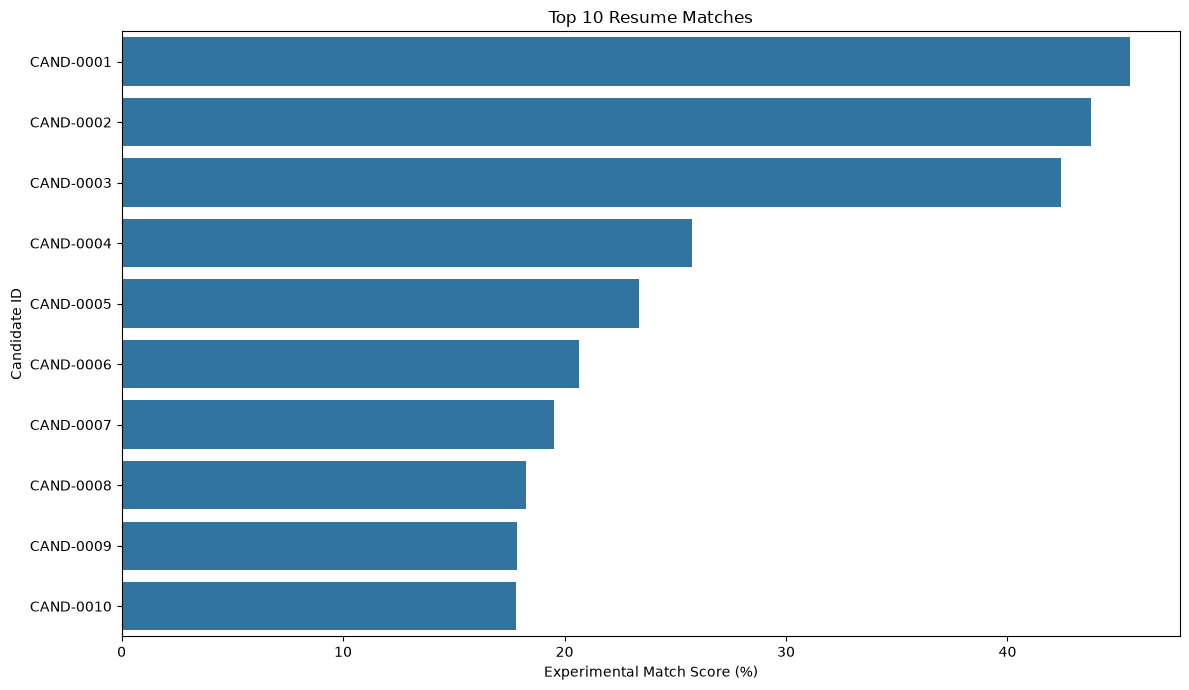

In [49]:
top_candidates = ranked_candidates.head(10).copy()

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_candidates,
    x='Final_Score',
    y='Candidate_ID'
)

plt.title("Top 10 Resume Matches")
plt.xlabel("Experimental Match Score (%)")
plt.ylabel("Candidate ID")

plt.tight_layout()
plt.show()

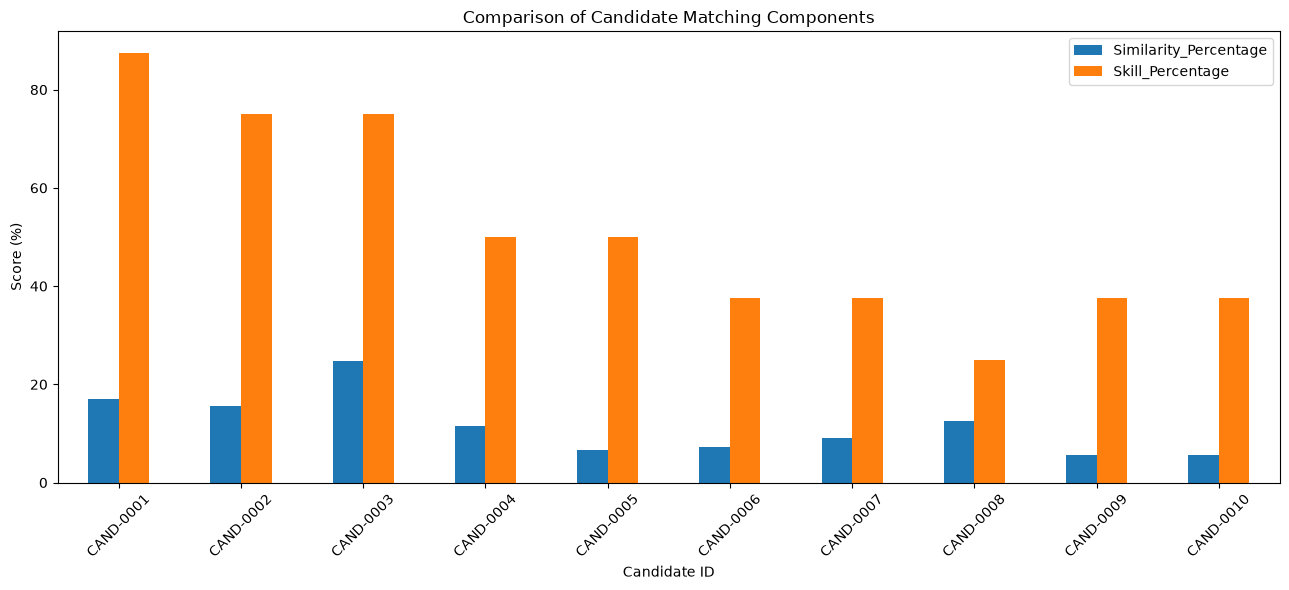

In [50]:
top_candidates.set_index('Candidate_ID')[
    [
        'Similarity_Percentage',
        'Skill_Percentage'
    ]
].plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title("Comparison of Candidate Matching Components")
plt.ylabel("Score (%)")
plt.xlabel("Candidate ID")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [51]:
def candidate_report(candidate_id):

    candidate = ranked_candidates[
        ranked_candidates['Candidate_ID'] == candidate_id
    ]

    if candidate.empty:
        print("Candidate not found.")
        return

    candidate = candidate.iloc[0]

    print("=" * 55)
    print("RESUME SCREENING REPORT")
    print("=" * 55)

    print("Candidate:", candidate['Candidate_ID'])

    print("Resume Category:", candidate['Category'])

    print("Rank:", candidate['Rank'])

    print(
        "Final Match Score:",
        round(candidate['Final_Score'], 2), "%"
    )

    print(
        "Text Similarity:",
        round(candidate['Similarity_Percentage'], 2), "%"
    )

    print(
        "Required Skill Match:",
        round(candidate['Skill_Percentage'], 2), "%"
    )

    print("\nMatched Skills:")

    for skill in candidate['Matched_Skills']:
        print("-", skill)

    print("\nMissing Skills:")

    for skill in candidate['Missing_Skills']:
        print("-", skill)

    print("\nAll Detected Skills:")

    for skill in candidate['Extracted_Skills']:
        print("-", skill)

    print("=" * 55)

In [52]:
candidate_report('CAND-0001')

RESUME SCREENING REPORT
Candidate: CAND-0001
Resume Category: Data Science
Rank: 1
Final Match Score: 45.51 %
Text Similarity: 17.03 %
Required Skill Match: 87.5 %

Matched Skills:
- pandas
- numpy
- python
- deep learning
- tensorflow
- machine learning
- sql

Missing Skills:
- scikit-learn

All Detected Skills:
- python
- java
- c++
- sql
- mysql
- machine learning
- deep learning
- artificial intelligence
- natural language processing
- pandas
- numpy
- tensorflow
- data science
- linux
- neural networks


In [53]:
ranked_candidates[
    [
        'Rank',
        'Candidate_ID',
        'Category',
        'Final_Score',
        'Similarity_Percentage',
        'Skill_Percentage',
        'Matched_Skills',
        'Missing_Skills'
    ]
].to_csv(
    'resume_screening_results.csv',
    index=False
)

print("Results exported successfully!")

Results exported successfully!
